# Klasifikasi Grade Nutri-Score (A–E) Produk Makanan Kemasan
**Proyek Supervised Learning · Pipeline end-to-end tanpa kebocoran data**

**Pertanyaan penelitian**
1. Seberapa akurat grade Nutri-Score (A–E) dapat diprediksi dari kandungan gizi, jenis produk, dan alergen?
2. Fitur mana yang paling berpengaruh, dan apakah fitur rekayasa berbasis pengetahuan domain (poin Nutri-Score) benar-benar membantu?
3. Karena grade bersifat *berurutan* (A < B < C < D < E), apakah pendekatan **ordinal** lebih baik daripada klasifikasi biasa?

**Alur kerja (setiap tahap ada di sel terpisah)**
`Setup → Load Data → Audit → Cleaning (decision log) → EDA + Uji Statistik → Split (group-aware) → Pipeline → Baseline → Cross-Validation → Tuning → Model Ordinal & Ensemble → Evaluasi Test → Ablasi Fitur → Interpretasi → Analisis Error → Simpan Model & API → Kesimpulan`

**Prinsip yang dijaga agar penilaian kuat**
- Pembagian data memakai **group split** (produk/merek yang sama tidak muncul di train dan test sekaligus), sehingga tidak ada *near-duplicate leakage*.
- Imputasi, scaling, dan encoding dipelajari **hanya dari data latih** (di dalam `Pipeline`).
- Data uji dipakai **satu kali** di akhir; pemilihan model memakai cross-validation pada data latih.
- Setiap keputusan pembersihan dicatat di *decision log* beserta jumlah baris/nilai yang terdampak.

## 1. Setup & Konfigurasi
Tahap ini mengimpor library, menetapkan *random seed* agar hasil bisa direproduksi, dan menyiapkan folder keluaran.

In [ ]:
import os, sys, json, warnings, platform  # modul sistem, JSON, peringatan, info platform
import numpy as np  # operasi numerik
import pandas as pd  # manipulasi tabel
import matplotlib.pyplot as plt  # visualisasi dasar
import seaborn as sns  # visualisasi statistik
import sqlite3  # membaca database SQLite hasil integrasi
import joblib  # menyimpan model
import sklearn  # untuk mencatat versi sklearn
from scipy import stats  # uji statistik (Kruskal-Wallis, Spearman)
warnings.filterwarnings("ignore")  # sembunyikan peringatan agar output rapi
pd.set_option("display.max_columns", 60)  # tampilkan semua kolom tabel
pd.set_option("display.width", 200)  # lebar tampilan tabel
sns.set_theme(style="whitegrid", context="notebook")  # tema grafik seragam
SEED = 42  # seed global untuk reproduksibilitas
np.random.seed(SEED)  # kunci seed numpy
GRADES = ["A", "B", "C", "D", "E"]  # urutan grade dari terbaik ke terburuk
GRADE_TO_INT = {g: i for i, g in enumerate(GRADES)}  # pemetaan grade ke angka ordinal
OUT_DIR = "outputs_nutriscore"  # folder keluaran model dan laporan
os.makedirs(OUT_DIR, exist_ok=True)  # buat folder bila belum ada
print("Python", platform.python_version(), "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)  # catat versi

Python 3.12.3 | pandas 3.0.6 | scikit-learn 1.9.1


### 1b. Modul fitur (ditulis ke file agar model bisa disimpan & dipakai di API)
Fungsi pembersihan nilai mustahil dan rekayasa fitur diletakkan di file `nutriscore_utils.py`. Semua operasinya **baris-per-baris** (tidak mempelajari apa pun dari seluruh data), sehingga aman dari kebocoran data dan bisa dipanggil ulang saat deployment.

In [ ]:
%%writefile nutriscore_utils.py
"""Modul pendukung proyek klasifikasi Nutri-Score (fitur baris-per-baris, tanpa kebocoran data)."""
import numpy as np  # library numerik untuk operasi array
import pandas as pd  # library tabel data
from sklearn.base import BaseEstimator, ClassifierMixin, clone  # kelas dasar estimator sklearn

# ---------------------------------------------------------------- konstanta kolom
NUTRIENT_COLS = [  # daftar kolom kandungan gizi per 100 g
    "energy_kcal", "fat_100g", "saturated_fat_100g", "carbs_100g",  # energi, lemak, lemak jenuh, karbohidrat
    "sugars_100g", "fiber_100g", "proteins_100g", "salt_100g", "sodium_100g",  # gula, serat, protein, garam, natrium
]  # akhir daftar kolom gizi
ALLERGEN_COLS = [  # daftar kolom penanda alergen (boolean)
    "contains_gluten", "contains_dairy", "contains_nuts",  # gluten, susu, kacang
    "contains_soy", "contains_eggs", "contains_fish",  # kedelai, telur, ikan
]  # akhir daftar alergen
RAW_INPUT_COLS = NUTRIENT_COLS + ["categories"] + ALLERGEN_COLS  # kolom mentah minimum yang dibutuhkan model
ENGINEERED_NUM = ["sugar_to_carb", "sat_to_fat", "macro_sum", "fiber_missing"]  # fitur rasio hasil rekayasa
POINT_NUM = [  # fitur poin pendekatan algoritma Nutri-Score
    "p_energy", "p_sugar", "p_satfat", "p_sodium", "p_fiber", "p_protein",  # poin per komponen
    "neg_points", "pos_points", "nutri_points",  # total poin negatif, positif, dan skor akhir
]  # akhir daftar poin
CATEGORY_FLAGS = [  # flag kategori produk dari teks 'categories'
    "is_beverage", "is_water", "is_cheese", "is_fat_oil",  # minuman, air, keju, lemak/minyak
    "is_fruitveg", "is_dairy", "is_snack", "is_cereal", "is_sweet",  # buah-sayur, susu, camilan, serealia, manis
]  # akhir daftar flag
CATEGORY_CAT = ["main_category"]  # kolom kategorikal kategori utama
# pola regex untuk tiap flag kategori
_FLAG_PATTERNS = {  # kamus nama flag -> pola teks
    "is_beverage": "beverage",  # minuman
    "is_water": "waters",  # air mineral
    "is_cheese": "cheese",  # keju
    "is_fat_oil": r"en:fats|oils",  # lemak dan minyak
    "is_fruitveg": "fruits|vegetables|legumes",  # buah, sayur, kacang-kacangan
    "is_dairy": "dairies|milk",  # produk susu
    "is_snack": "snacks",  # camilan
    "is_cereal": "cereals",  # serealia
    "is_sweet": "sweet|cocoa|biscuits|chocolate",  # produk manis
}  # akhir kamus pola


# ---------------------------------------------------------------- normalisasi tipe data
def normalize_types(df):
    """Ubah kolom gizi/NOVA menjadi numerik dan kolom alergen menjadi 0/1 (database SQLite menyimpan semuanya sebagai teks)."""
    out = df.copy()  # salin agar data asli tidak berubah
    for col in NUTRIENT_COLS + ["nova_group"]:  # kolom yang seharusnya numerik
        if col in out.columns:  # hanya jika kolom ada
            out[col] = pd.to_numeric(out[col], errors="coerce")  # teks tidak valid menjadi NaN
    for col in ALLERGEN_COLS:  # kolom alergen
        if col in out.columns:  # hanya jika kolom ada
            out[col] = out[col].astype(str).str.strip().str.lower().isin(["true", "1", "1.0", "yes", "t"]).astype(int)  # teks/boolean -> 0/1
    return out  # kembalikan data bertipe benar


# ---------------------------------------------------------------- pembersihan nilai tidak wajar
def clean_nutrients(df):
    """Ubah nilai gizi yang mustahil secara fisik menjadi NaN (aturan baris-per-baris)."""
    out = df.copy()  # salin agar data asli tidak berubah
    for col in NUTRIENT_COLS[1:]:  # semua kolom gram per 100 g (selain energi)
        out[col] = pd.to_numeric(out[col], errors="coerce")  # paksa menjadi numerik
        out.loc[(out[col] > 100) | (out[col] < 0), col] = np.nan  # >100 g atau negatif per 100 g mustahil
    out["energy_kcal"] = pd.to_numeric(out["energy_kcal"], errors="coerce")  # energi numerik
    out.loc[(out["energy_kcal"] > 900) | (out["energy_kcal"] < 0), "energy_kcal"] = np.nan  # maksimum fisik lemak murni = 900 kcal
    out.loc[out["saturated_fat_100g"] > out["fat_100g"] + 1e-9, "saturated_fat_100g"] = np.nan  # lemak jenuh tak boleh > lemak total
    out.loc[out["sugars_100g"] > out["carbs_100g"] + 1e-9, "sugars_100g"] = np.nan  # gula tak boleh > karbohidrat total
    return out  # kembalikan data bersih


# ---------------------------------------------------------------- poin Nutri-Score (pendekatan)
def _points(series, thresholds):
    """Hitung poin = jumlah ambang yang dilewati nilai; NaN dipertahankan."""
    values = series.astype(float)  # pastikan tipe float
    pts = pd.Series(0.0, index=values.index)  # mulai dari 0 poin
    for t in thresholds:  # untuk setiap ambang
        pts = pts + (values > t).astype(float)  # tambah 1 poin bila nilai melewati ambang
    pts[values.isna()] = np.nan  # nilai kosong -> poin kosong
    return pts  # kembalikan poin


def prepare_features(df):
    """Bersihkan nilai mustahil lalu tambahkan fitur turunan. Tidak ada parameter yang dipelajari dari data."""
    out = clean_nutrients(normalize_types(df))  # samakan tipe data lalu bersihkan nilai tidak wajar
    cat = out["categories"].fillna("").astype(str).str.lower()  # teks kategori huruf kecil
    for name, pattern in _FLAG_PATTERNS.items():  # untuk tiap flag kategori
        out[name] = cat.str.contains(pattern, regex=True).astype(int)  # 1 bila pola ditemukan
    first = cat.str.split(",").str[0].str.strip()  # kategori pertama (paling umum)
    out["main_category"] = first.where(first != "", "unknown")  # kategori utama; kosong -> unknown
    out["sugar_to_carb"] = out["sugars_100g"] / (out["carbs_100g"] + 1e-3)  # proporsi gula dalam karbohidrat
    out["sat_to_fat"] = out["saturated_fat_100g"] / (out["fat_100g"] + 1e-3)  # proporsi lemak jenuh dalam lemak
    out["macro_sum"] = out[["fat_100g", "carbs_100g", "proteins_100g"]].sum(axis=1, skipna=False)  # total makronutrien per 100 g
    out["fiber_missing"] = out["fiber_100g"].isna().astype(int)  # penanda serat tidak dilaporkan
    out["p_energy"] = _points(out["energy_kcal"] * 4.184, [335 * i for i in range(1, 11)])  # poin energi (kJ)
    out["p_sugar"] = _points(out["sugars_100g"], [4.5 * i for i in range(1, 11)])  # poin gula
    out["p_satfat"] = _points(out["saturated_fat_100g"], list(range(1, 11)))  # poin lemak jenuh
    out["p_sodium"] = _points(out["sodium_100g"] * 1000, [90 * i for i in range(1, 11)])  # poin natrium (mg)
    out["p_fiber"] = _points(out["fiber_100g"], [0.9, 1.9, 2.8, 3.7, 4.7])  # poin serat (positif)
    out["p_protein"] = _points(out["proteins_100g"], [1.6, 3.2, 4.8, 6.4, 8.0])  # poin protein (positif)
    out["neg_points"] = out[["p_energy", "p_sugar", "p_satfat", "p_sodium"]].sum(axis=1, skipna=False)  # total poin negatif
    out["pos_points"] = out[["p_fiber", "p_protein"]].sum(axis=1, skipna=True)  # total poin positif (serat kosong dianggap 0)
    out["nutri_points"] = out["neg_points"] - out["pos_points"]  # skor gizi pendekatan (makin kecil makin sehat)
    return out  # kembalikan data dengan fitur lengkap (alergen sudah 0/1 dari normalize_types)


def rule_based_grade(df):
    """Baseline non-ML: ubah skor poin pendekatan menjadi grade A-E memakai ambang resmi (tanpa poin buah/sayur)."""
    score = df["nutri_points"].to_numpy(dtype=float)  # skor gizi
    is_bev = df["is_beverage"].to_numpy(dtype=int) == 1  # penanda minuman
    food = np.select([score <= -1, score <= 2, score <= 10, score <= 18], [0, 1, 2, 3], default=4)  # ambang makanan umum
    bev = np.select([score <= 1, score <= 5, score <= 9], [1, 2, 3], default=4)  # ambang minuman (A hanya untuk air)
    bev = np.where(df["is_water"].to_numpy(dtype=int) == 1, 0, bev)  # air mineral -> grade A
    pred = np.where(is_bev, bev, food)  # pilih ambang sesuai jenis produk
    pred = np.where(np.isnan(score), 2, pred)  # skor kosong -> tebak kelas tengah (C)
    return pred.astype(int)  # kembalikan indeks grade 0..4


# ---------------------------------------------------------------- klasifier ordinal
class OrdinalClassifier(ClassifierMixin, BaseEstimator):
    """Klasifier ordinal pendekatan Frank & Hall: K-1 model biner untuk P(y > k)."""

    def __init__(self, base_estimator=None):  # konstruktor menerima estimator dasar
        self.base_estimator = base_estimator  # simpan estimator dasar

    def fit(self, X, y):  # latih K-1 model biner
        y = np.asarray(y)  # pastikan array numpy
        self.classes_ = np.sort(np.unique(y))  # daftar kelas terurut
        self.models_ = []  # tempat menyimpan model biner
        for k in self.classes_[:-1]:  # untuk setiap ambang kelas
            model = clone(self.base_estimator)  # salin estimator dasar yang belum dilatih
            model.fit(X, (y > k).astype(int))  # latih untuk memprediksi apakah y > k
            self.models_.append(model)  # simpan model
        return self  # kembalikan diri sendiri

    def predict_proba(self, X):  # hitung probabilitas tiap kelas
        gt = np.column_stack([m.predict_proba(X)[:, 1] for m in self.models_])  # matriks P(y > k)
        n_cls = len(self.classes_)  # jumlah kelas
        probs = np.zeros((gt.shape[0], n_cls))  # tempat probabilitas kelas
        probs[:, 0] = 1 - gt[:, 0]  # P(y = kelas pertama)
        for i in range(1, n_cls - 1):  # kelas-kelas tengah
            probs[:, i] = gt[:, i - 1] - gt[:, i]  # P(y > i-1) - P(y > i)
        probs[:, -1] = gt[:, -1]  # P(y = kelas terakhir)
        probs = np.clip(probs, 1e-9, None)  # hindari probabilitas negatif akibat ketidakkonsistenan
        return probs / probs.sum(axis=1, keepdims=True)  # normalisasi agar jumlah = 1

    def predict(self, X):  # prediksi kelas
        return self.classes_[np.argmax(self.predict_proba(X), axis=1)]  # kelas dengan probabilitas terbesar

Overwriting nutriscore_utils.py


In [ ]:
sys.path.insert(0, os.getcwd())  # pastikan folder kerja bisa mengimpor modul lokal
import importlib  # untuk memuat ulang modul bila diedit
import nutriscore_utils as nu  # modul fitur yang baru ditulis
importlib.reload(nu)  # muat ulang agar versi terbaru terpakai
print("Modul dimuat. Jumlah kolom mentah yang dibutuhkan model:", len(nu.RAW_INPUT_COLS))  # konfirmasi

Modul dimuat. Jumlah kolom mentah yang dibutuhkan model: 16


## 2. Memuat Data
Sumber utama adalah tabel `nutriscore_master` pada database `datawrangling_fix_supervised.db` (hasil integrasi SQL dua dataset Kaggle: *foods_health_scores_allergens* dan *foods_dietary_restrictions*). Bila file `.db` tidak ditemukan, notebook memakai `nutriscore_master.csv` sebagai cadangan.
Di Google Colab, bila file belum ada, akan muncul dialog upload.

In [ ]:
def find_file(name):  # cari file di beberapa lokasi umum
    for folder in [".", "/content", "/content/drive/MyDrive", "/mnt/user-data/uploads"]:  # lokasi yang dicek
        path = os.path.join(folder, name)  # gabungkan folder dan nama file
        if os.path.exists(path):  # jika file ada
            return path  # kembalikan path-nya
    return None  # tidak ditemukan


db_path = find_file("datawrangling_fix_supervised.db")  # cari database
csv_path = find_file("nutriscore_master.csv")  # cari CSV cadangan
if db_path is None and csv_path is None:  # jika keduanya tidak ada
    try:  # coba dialog upload Colab
        from google.colab import files  # modul upload Colab
        files.upload()  # minta pengguna mengunggah file
        db_path = find_file("datawrangling_fix_supervised.db")  # cari ulang database
        csv_path = find_file("nutriscore_master.csv")  # cari ulang CSV
    except ImportError:  # bukan di Colab
        raise FileNotFoundError("Letakkan datawrangling_fix_supervised.db atau nutriscore_master.csv di folder kerja.")  # pesan jelas

if db_path:  # jika database tersedia
    conn = sqlite3.connect(db_path)  # buka koneksi SQLite
    tables = pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table'", conn)["name"].tolist()  # daftar tabel
    print("Tabel di database:", tables)  # tampilkan tabel
    for t in tables:  # hitung baris tiap tabel
        n = pd.read_sql_query(f"SELECT COUNT(*) AS n FROM {t}", conn)["n"][0]  # jumlah baris
        print(f"  - {t}: {n:,} baris")  # cetak ringkasan
    df_raw = pd.read_sql_query("SELECT * FROM nutriscore_master", conn)  # muat tabel master
    conn.close()  # tutup koneksi
    source = "SQLite: nutriscore_master"  # catat sumber
else:  # fallback ke CSV
    df_raw = pd.read_csv(csv_path)  # muat CSV master
    source = "CSV: nutriscore_master.csv"  # catat sumber
print(f"\nSumber data: {source} | bentuk: {df_raw.shape[0]:,} baris x {df_raw.shape[1]} kolom")  # ringkasan akhir
print("Tipe data hasil muat:", df_raw.dtypes.astype(str).value_counts().to_dict())  # SQLite sering menyimpan semua kolom sebagai teks
na_before = df_raw.isna().sum().sum()  # jumlah NaN sebelum konversi tipe
df_raw = nu.normalize_types(df_raw)  # kolom gizi -> numerik, alergen -> 0/1
print("Sel kosong baru akibat konversi tipe (nilai non-numerik):", int(df_raw.isna().sum().sum() - na_before))  # transparansi konversi
df_raw.head()  # tampilkan 5 baris pertama

Tabel di database: ['foods_dietary_restrictions', 'foods_health_scores_allergens', 'nutriscore_master']
  - foods_dietary_restrictions: 4,997 baris
  - foods_health_scores_allergens: 4,997 baris
  - nutriscore_master: 5,052 baris

Sumber data: SQLite: nutriscore_master | bentuk: 5,052 baris x 22 kolom
Tipe data hasil muat: {'str': 22}
Sel kosong baru akibat konversi tipe (nilai non-numerik): 0


,product_name,brands,categories,nutriscore_grade,nova_group,ecoscore_grade,energy_kcal,fat_100g,saturated_fat_100g,carbs_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g,sodium_100g,contains_gluten,contains_dairy,contains_nuts,contains_soy,contains_eggs,contains_fish,food_type
0,Sidi Ali,سيدي علي,"en:beverages-and-beverages-preparations, en:be...",A,NaN,NOT-APPLICABLE,0.0,0.0,0.0,4.2,1.4,0.0,0.0,0.000000,0.000000,0,0,0,0,0,0,Branded/Packaged
1,Sidi Ali,Sidi Ali,"en:beverages-and-beverages-preparations, en:be...",A,1.0,NOT-APPLICABLE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.065000,0.026000,0,0,0,0,0,0,Branded/Packaged
2,Eau minérale naturelle,sidi ali,"en:beverages-and-beverages-preparations, en:be...",A,1.0,NOT-APPLICABLE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.065000,0.026000,0,0,0,0,0,0,Branded/Packaged
3,اكوافينا,AQUAFINA,"en:beverages-and-beverages-preparations, en:be...",A,NaN,NOT-APPLICABLE,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000508,0.000203,0,0,0,0,0,0,Branded/Packaged
4,Lait,Jaouda,"en:dairies, en:meals, en:milks-liquid-and-powder",B,3.0,D,45.0,1.5,1.0,4.9,0.0,NaN,3.1,0.225000,0.090000,0,1,0,0,0,0,Branded/Packaged


## 3. Audit Kualitas Data (sebelum dibersihkan)
Audit dilakukan **sebelum** mengubah apa pun agar setiap keputusan pembersihan punya dasar angka: tipe data, missing value, duplikat, label tidak valid, dan nilai gizi yang mustahil.

,tipe,missing,missing_%,n_unik
fiber_100g,float64,1410,27.91,379
nova_group,float64,302,5.98,4
saturated_fat_100g,float64,146,2.89,515
sugars_100g,float64,135,2.67,660
energy_kcal,float64,130,2.57,875
carbs_100g,float64,126,2.49,761
proteins_100g,float64,113,2.24,491
fat_100g,float64,111,2.20,676
brands,str,106,2.10,1946
product_name,str,105,2.08,4138


Baris duplikat penuh      : 480
Distribusi label mentah   :
nutriscore_grade
C                 1195
E                 1122
D                 1016
A                  882
B                  700
NOT-APPLICABLE     137

Nilai gizi mustahil secara fisik:
  - gram > 100 per 100 g: 14
  - energi > 900 kcal: 3
  - lemak jenuh > lemak total: 5
  - gula > karbohidrat: 13

Nilai maksimum serat (g/100 g): 6111242106933.0


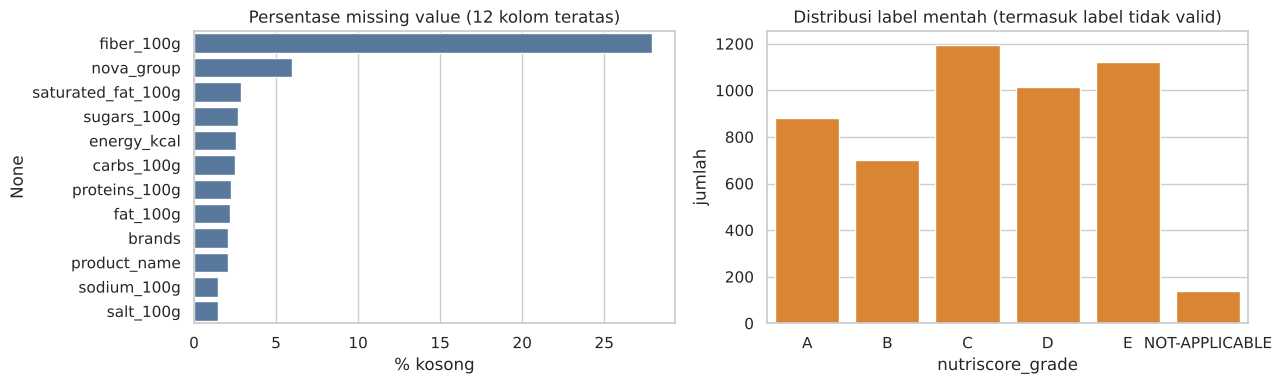

In [ ]:
audit = pd.DataFrame({  # tabel ringkasan per kolom
    "tipe": df_raw.dtypes.astype(str),  # tipe data
    "missing": df_raw.isna().sum(),  # jumlah nilai kosong
    "missing_%": (df_raw.isna().mean() * 100).round(2),  # persentase kosong
    "n_unik": df_raw.nunique(),  # jumlah nilai unik
})  # akhir tabel audit
display(audit.sort_values("missing_%", ascending=False))  # urutkan dari yang paling kosong

print("Baris duplikat penuh      :", df_raw.duplicated().sum())  # duplikat persis
print("Distribusi label mentah   :")  # judul
print(df_raw["nutriscore_grade"].astype(str).str.strip().str.upper().value_counts(dropna=False).to_string())  # sebaran label termasuk yang tidak valid

nut = nu.NUTRIENT_COLS  # kolom gizi
impossible = {  # hitung nilai mustahil per aturan
    "gram > 100 per 100 g": int((df_raw[nut[1:]].apply(pd.to_numeric, errors="coerce") > 100).sum().sum()),  # kolom gram >100
    "energi > 900 kcal": int((pd.to_numeric(df_raw["energy_kcal"], errors="coerce") > 900).sum()),  # energi mustahil
    "lemak jenuh > lemak total": int((df_raw["saturated_fat_100g"] > df_raw["fat_100g"]).sum()),  # lemak jenuh melebihi total
    "gula > karbohidrat": int((df_raw["sugars_100g"] > df_raw["carbs_100g"]).sum()),  # gula melebihi karbohidrat
}  # akhir kamus
print("\nNilai gizi mustahil secara fisik:")  # judul
for k, v in impossible.items():  # cetak tiap aturan
    print(f"  - {k}: {v}")  # jumlah pelanggaran
print("\nNilai maksimum serat (g/100 g):", df_raw["fiber_100g"].max())  # contoh outlier ekstrem

fig, ax = plt.subplots(1, 2, figsize=(13, 4))  # dua panel grafik
miss = (df_raw.isna().mean() * 100).sort_values(ascending=False).head(12)  # 12 kolom paling kosong
sns.barplot(x=miss.values, y=miss.index, ax=ax[0], color="#4C78A8")  # bar missing value
ax[0].set_title("Persentase missing value (12 kolom teratas)")  # judul panel 1
ax[0].set_xlabel("% kosong")  # label sumbu x
order = ["A", "B", "C", "D", "E", "NOT-APPLICABLE"]  # urutan label
lbl = df_raw["nutriscore_grade"].astype(str).str.strip().str.upper().value_counts().reindex(order).fillna(0)  # hitung label
sns.barplot(x=lbl.index, y=lbl.values, ax=ax[1], color="#F58518")  # bar distribusi label
ax[1].set_title("Distribusi label mentah (termasuk label tidak valid)")  # judul panel 2
ax[1].set_ylabel("jumlah")  # label sumbu y
plt.tight_layout()  # rapikan tata letak
plt.show()  # tampilkan grafik

## 4. Data Cleaning dengan *Decision Log*
Setiap langkah mencatat **apa** yang dilakukan, **berapa** yang terdampak, dan **kenapa**. Prinsipnya:
- Label tidak valid dan duplikat penuh dibuang (mengganggu evaluasi).
- Nilai gizi yang mustahil secara fisik dijadikan `NaN` (bukan dibuang), lalu diimputasi **di dalam pipeline** setelah split agar tidak bocor.
- Baris tanpa satu pun informasi gizi dibuang karena tidak mungkin diprediksi.

In [ ]:
log = [["Normalisasi tipe data", df_raw.shape[1], "-", "Kolom gizi/NOVA dijadikan numerik, alergen dijadikan 0/1 (database menyimpan semuanya sebagai teks)"]]  # daftar catatan keputusan pembersihan
df = df_raw.copy()  # salin data mentah
n0 = len(df)  # jumlah baris awal

for col in ["nutriscore_grade", "ecoscore_grade", "food_type", "product_name", "brands", "categories"]:  # kolom teks
    df[col] = df[col].astype("string").str.strip()  # hapus spasi berlebih
df["nutriscore_grade"] = df["nutriscore_grade"].str.upper()  # samakan huruf kapital label
df["ecoscore_grade"] = df["ecoscore_grade"].str.upper()  # samakan huruf kapital ecoscore
log.append(["Standardisasi teks", "kolom teks", "-", "Spasi/huruf kapital diseragamkan agar kategori tidak terpecah"])  # catat

invalid = ~df["nutriscore_grade"].isin(GRADES)  # label di luar A-E
log.append(["Buang label tidak valid", int(invalid.sum()), f"{invalid.sum()} baris", "Target harus A-E agar bisa dievaluasi"])  # catat
df = df[~invalid].copy()  # buang baris label tidak valid

dup = df.duplicated()  # duplikat penuh
log.append(["Buang duplikat penuh", int(dup.sum()), f"{dup.sum()} baris", "Duplikat menggelembungkan skor evaluasi"])  # catat
df = df.drop_duplicates().copy()  # buang duplikat

before = df[nu.NUTRIENT_COLS].isna().sum().sum()  # NaN gizi sebelum pembersihan
df_clean_vals = nu.clean_nutrients(df)  # ubah nilai mustahil menjadi NaN
after = df_clean_vals[nu.NUTRIENT_COLS].isna().sum().sum()  # NaN gizi sesudah
log.append(["Nilai gizi mustahil -> NaN", int(after - before), f"{after - before} sel", "Aturan fisik: <=100 g/100 g, energi <=900 kcal, lemak jenuh <= lemak, gula <= karbohidrat"])  # catat
df = df_clean_vals  # pakai data yang sudah dibersihkan

no_info = df[nu.NUTRIENT_COLS].isna().all(axis=1)  # baris tanpa data gizi sama sekali
log.append(["Buang baris tanpa data gizi", int(no_info.sum()), f"{no_info.sum()} baris", "Tidak ada sinyal untuk diprediksi"])  # catat
df = df[~no_info].copy()  # buang baris tersebut

df["nova_group"] = pd.to_numeric(df["nova_group"], errors="coerce")  # NOVA numerik (NaN bila kosong)
df["ecoscore_grade"] = df["ecoscore_grade"].replace({"UNKNOWN": pd.NA, "NOT-APPLICABLE": pd.NA})  # ecoscore tidak valid -> kosong
log.append(["Ecoscore UNKNOWN/NOT-APPLICABLE -> NaN", int(df["ecoscore_grade"].isna().sum()), "-", "Dipakai hanya pada skenario ablasi, bukan model utama"])  # catat

df = df.reset_index(drop=True)  # rapikan indeks
y = df["nutriscore_grade"].map(GRADE_TO_INT).astype(int).to_numpy()  # target ordinal 0-4
groups = (df["product_name"].fillna("na").str.lower() + "|" + df["brands"].fillna("na").str.lower()).to_numpy()  # kunci grup produk-merek
log.append(["Hasil akhir", len(df), f"dari {n0:,} -> {len(df):,} baris", f"{len(np.unique(groups)):,} grup produk-merek unik"])  # catat

decision_log = pd.DataFrame(log, columns=["Langkah", "Jumlah terdampak", "Keterangan", "Alasan"])  # tabel log
display(decision_log)  # tampilkan log
decision_log.to_csv(f"{OUT_DIR}/decision_log.csv", index=False)  # simpan log

,Langkah,Jumlah terdampak,Keterangan,Alasan
0,Normalisasi tipe data,22,-,"Kolom gizi/NOVA dijadikan numerik, alergen dij..."
1,Standardisasi teks,kolom teks,-,Spasi/huruf kapital diseragamkan agar kategori...
2,Buang label tidak valid,137,137 baris,Target harus A-E agar bisa dievaluasi
3,Buang duplikat penuh,478,478 baris,Duplikat menggelembungkan skor evaluasi
4,Nilai gizi mustahil -> NaN,33,33 sel,"Aturan fisik: <=100 g/100 g, energi <=900 kcal..."
5,Buang baris tanpa data gizi,32,32 baris,Tidak ada sinyal untuk diprediksi
6,Ecoscore UNKNOWN/NOT-APPLICABLE -> NaN,789,-,"Dipakai hanya pada skenario ablasi, bukan mode..."
7,Hasil akhir,4405,"dari 5,052 -> 4,405 baris","4,237 grup produk-merek unik"


## 5. Rekayasa Fitur (berbasis pengetahuan domain)
Nutri-Score dihitung dari komponen **negatif** (energi, gula, lemak jenuh, natrium) dikurangi komponen **positif** (serat, protein, buah/sayur). Karena itu fitur dirancang mengikuti logika tersebut:

| Kelompok | Isi | Alasan |
|---|---|---|
| Nutrisi mentah | 9 kolom gizi per 100 g | Sinyal dasar |
| Rasio | gula/karbohidrat, lemak jenuh/lemak, total makro, penanda serat kosong | Komposisi lebih informatif daripada angka mentah |
| Poin Nutri-Score | poin tiap komponen + skor akhir pendekatan | Memasukkan struktur algoritma resmi ke model |
| Kategori produk | minuman, air, keju, lemak/minyak, buah-sayur, dll. + kategori utama | Minuman & lemak memakai ambang berbeda |
| Alergen | 6 penanda | Konteks formulasi produk |

**Fitur sengaja tidak dipakai di model utama:** `nova_group` dan `ecoscore_grade`. Keduanya adalah skor turunan lain (tingkat pemrosesan & dampak lingkungan) yang bukan komponen perhitungan Nutri-Score; dampaknya diuji terpisah di bagian ablasi.

In [ ]:
FEATURES_NUM = nu.NUTRIENT_COLS + nu.ENGINEERED_NUM + nu.POINT_NUM + nu.CATEGORY_FLAGS + nu.ALLERGEN_COLS  # fitur numerik model utama
FEATURES_CAT = nu.CATEGORY_CAT  # fitur kategorikal model utama
X = df[nu.RAW_INPUT_COLS + ["nova_group", "ecoscore_grade"]].copy()  # data mentah (nova/eco hanya untuk ablasi)
X_feat = nu.prepare_features(X)  # hitung fitur turunan (hanya untuk EDA)
print("Jumlah fitur model utama:", len(FEATURES_NUM) + len(FEATURES_CAT))  # ringkasan
print("Kategori utama teratas:")  # judul
print(X_feat["main_category"].value_counts().head(8).to_string())  # kategori utama terbanyak
X_feat[["energy_kcal", "sugars_100g", "nutri_points", "is_beverage"]].head()  # contoh fitur turunan

Jumlah fitur model utama: 38
Kategori utama teratas:
main_category
en:plant-based-foods-and-beverages         1780
en:snacks                                   818
en:dairies                                  586
en:beverages-and-beverages-preparations     427
en:condiments                               262
en:breakfasts                                98
en:seafood                                   86
en:meats-and-their-products                  64


,energy_kcal,sugars_100g,nutri_points,is_beverage
0,0.0,1.4,0.0,1
1,NaN,NaN,NaN,1
2,NaN,NaN,NaN,1
3,0.0,0.0,0.0,1
4,45.0,0.0,-1.0,0


## 6. Exploratory Data Analysis + Uji Statistik
EDA di sini bertujuan menjawab: *apakah sinyal gizi memang membedakan grade?* Diuji dengan **Kruskal-Wallis** (beda sebaran antar grade) dan **korelasi Spearman** terhadap grade ordinal. Uji non-parametrik dipilih karena sebaran gizi sangat miring.

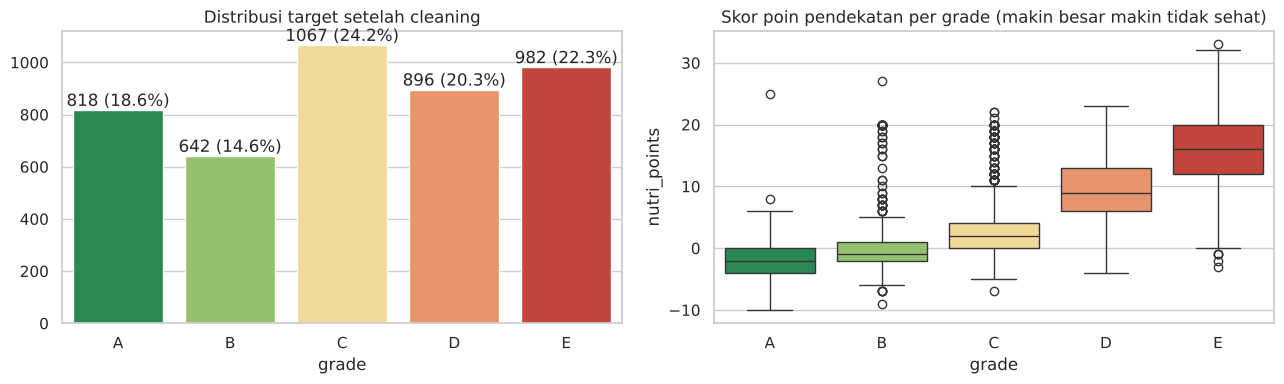

,fitur,n,H_Kruskal,p_value,epsilon_sq,spearman_rho
9,nutri_points,4291,2641.9,0.000000e+00,0.616,0.783
4,sugars_100g,4332,919.7,9.002301e-198,0.212,0.440
2,saturated_fat_100g,4336,863.1,1.663381e-185,0.199,0.444
0,energy_kcal,4344,649.0,3.926243e-139,0.149,0.379
1,fat_100g,4360,565.0,5.734434e-121,0.130,0.357
7,salt_100g,4399,359.1,1.884682e-76,0.082,0.221
8,sodium_100g,4400,359.3,1.710247e-76,0.082,0.222
5,fiber_100g,3284,178.7,1.430063e-37,0.054,-0.187
6,proteins_100g,4360,225.1,1.496291e-47,0.052,-0.181
3,carbs_100g,4346,214.5,2.801957e-45,0.049,0.200


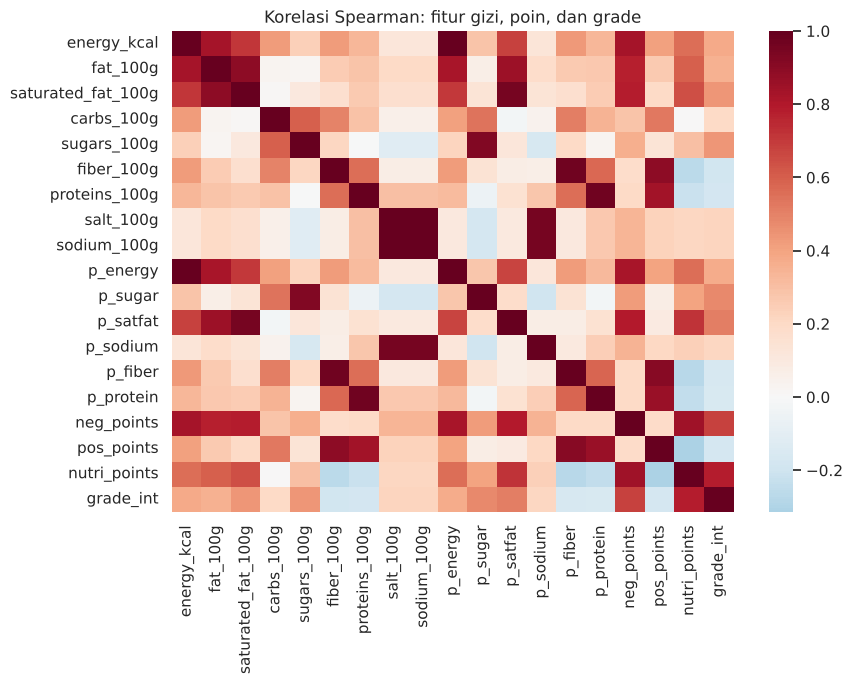

In [ ]:
eda = X_feat.copy()  # salinan untuk EDA
eda["grade"] = pd.Categorical(df["nutriscore_grade"], categories=GRADES, ordered=True)  # grade berurutan
eda["grade_int"] = y  # grade numerik

fig, ax = plt.subplots(1, 2, figsize=(13, 4))  # dua panel
cnt = eda["grade"].value_counts().reindex(GRADES)  # jumlah per grade
sns.barplot(x=cnt.index, y=cnt.values, ax=ax[0], palette=["#1a9850", "#91cf60", "#fee08b", "#fc8d59", "#d73027"])  # warna sesuai grade
for i, v in enumerate(cnt.values):  # label di atas bar
    ax[0].text(i, v, f"{v} ({v / cnt.sum():.1%})", ha="center", va="bottom")  # tampilkan jumlah dan persen
ax[0].set_title("Distribusi target setelah cleaning")  # judul
sns.boxplot(data=eda, x="grade", y="nutri_points", ax=ax[1], palette=["#1a9850", "#91cf60", "#fee08b", "#fc8d59", "#d73027"])  # skor poin per grade
ax[1].set_title("Skor poin pendekatan per grade (makin besar makin tidak sehat)")  # judul
plt.tight_layout()  # rapikan
plt.show()  # tampilkan

rows = []  # hasil uji tiap fitur gizi
for col in nu.NUTRIENT_COLS + ["nutri_points"]:  # tiap fitur
    sub = eda[[col, "grade_int"]].dropna()  # buang NaN untuk uji
    groups_k = [sub.loc[sub["grade_int"] == k, col].values for k in range(5)]  # data per grade
    h, p = stats.kruskal(*groups_k)  # uji Kruskal-Wallis
    rho, _ = stats.spearmanr(sub[col], sub["grade_int"])  # korelasi Spearman dengan grade
    eps2 = h / (len(sub) - 1)  # ukuran efek epsilon-kuadrat
    rows.append([col, len(sub), round(h, 1), p, round(eps2, 3), round(rho, 3)])  # simpan baris
tests = pd.DataFrame(rows, columns=["fitur", "n", "H_Kruskal", "p_value", "epsilon_sq", "spearman_rho"])  # tabel uji
display(tests.sort_values("epsilon_sq", ascending=False))  # urutkan berdasarkan ukuran efek

plt.figure(figsize=(9, 7))  # ukuran heatmap
corr = eda[nu.NUTRIENT_COLS + nu.POINT_NUM + ["grade_int"]].corr(method="spearman")  # korelasi Spearman
sns.heatmap(corr, cmap="RdBu_r", center=0, annot=False)  # heatmap korelasi
plt.title("Korelasi Spearman: fitur gizi, poin, dan grade")  # judul
plt.tight_layout()  # rapikan
plt.show()  # tampilkan

**Cara membaca hasil:** `epsilon_sq` mendekati 0 berarti efek kecil, mendekati 1 efek besar. Fitur dengan efek terbesar dan korelasi Spearman tinggi terhadap grade adalah kandidat prediktor terkuat. Skor poin `nutri_points` diharapkan paling kuat karena meniru struktur algoritma resmi.

## 7. Pembagian Data (Group-Aware Split)
Dataset berisi banyak produk dengan nama/merek sama (varian rasa, kemasan, dll.). Bila baris-baris mirip itu tersebar di train **dan** test, skor evaluasi menjadi terlalu optimis. Karena itu dipakai `StratifiedGroupKFold`: **grup produk-merek tidak pernah terbelah** antara train dan test, sementara proporsi kelas tetap terjaga. Sekitar 20% grup menjadi data uji yang disimpan sampai evaluasi akhir.

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold  # pembagi data berkelompok dan berstrata
X_model = X[nu.RAW_INPUT_COLS].copy()  # kolom mentah yang dipakai model final
X["ecoscore_grade"] = X["ecoscore_grade"].astype(object).where(X["ecoscore_grade"].notna(), np.nan)  # ubah pd.NA agar kompatibel dengan imputer
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)  # 5 lipatan -> 1 lipatan = 20% uji
train_idx, test_idx = next(splitter.split(X_model, y, groups))  # ambil lipatan pertama sebagai data uji
X_train, X_test = X_model.iloc[train_idx], X_model.iloc[test_idx]  # fitur train/test
y_train, y_test = y[train_idx], y[test_idx]  # target train/test
g_train, g_test = groups[train_idx], groups[test_idx]  # grup train/test
overlap = set(g_train) & set(g_test)  # irisan grup (harus kosong)
print(f"Train: {len(X_train):,} baris | Test: {len(X_test):,} baris | grup beririsan: {len(overlap)}")  # verifikasi tidak ada kebocoran
prop = pd.DataFrame({"train_%": np.bincount(y_train) / len(y_train) * 100, "test_%": np.bincount(y_test) / len(y_test) * 100}, index=GRADES).round(1)  # proporsi kelas
display(prop)  # tampilkan kesamaan proporsi kelas
assert len(overlap) == 0, "Ada grup produk yang bocor antara train dan test!"  # hentikan bila ada kebocoran

Train: 3,524 baris | Test: 881 baris | grup beririsan: 0


,train_%,test_%
A,18.6,18.6
B,14.6,14.5
C,24.2,24.2
D,20.3,20.3
E,22.3,22.4


## 8. Pipeline Pra-pemrosesan
Seluruh langkah ditempatkan di dalam `Pipeline` sehingga saat cross-validation **imputer, scaler, dan encoder hanya dipelajari dari lipatan latih**:
`rekayasa fitur → imputasi median (+ scaling bila model butuh) → one-hot kategori utama → model`.
Model berbasis pohon tidak butuh scaling; Logistic Regression dan KNN membutuhkannya.

In [ ]:
from sklearn.pipeline import Pipeline  # perangkai langkah pemrosesan
from sklearn.compose import ColumnTransformer  # transformasi per kelompok kolom
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler  # transformer dasar
from sklearn.impute import SimpleImputer  # pengisi nilai kosong


def build_pipeline(model, num_cols, cat_cols, scale=False):  # pabrik pipeline
    num_steps = [("imputer", SimpleImputer(strategy="median"))]  # imputasi median untuk numerik
    if scale:  # bila model sensitif skala
        num_steps.append(("scaler", StandardScaler()))  # standardisasi
    transformers = [("num", Pipeline(num_steps), num_cols)]  # blok numerik
    if cat_cols:  # bila ada kolom kategorikal
        cat_pipe = Pipeline([  # blok kategorikal
            ("imputer", SimpleImputer(strategy="constant", fill_value="missing")),  # isi kosong dengan 'missing'
            ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=30, sparse_output=False)),  # one-hot, kategori jarang digabung
        ])  # akhir blok kategorikal
        transformers.append(("cat", cat_pipe, cat_cols))  # tambahkan blok
    return Pipeline([  # pipeline lengkap
        ("features", FunctionTransformer(nu.prepare_features, validate=False)),  # rekayasa fitur baris-per-baris
        ("prep", ColumnTransformer(transformers)),  # pra-pemrosesan per kelompok kolom
        ("model", model),  # estimator
    ])  # akhir pipeline


from sklearn.ensemble import HistGradientBoostingClassifier  # model boosting untuk contoh
pipe_demo = build_pipeline(HistGradientBoostingClassifier(random_state=SEED), FEATURES_NUM, FEATURES_CAT)  # contoh pipeline
pipe_demo.fit(X_train, y_train)  # latih contoh untuk memastikan pipeline berjalan
n_out = pipe_demo.named_steps["prep"].transform(pipe_demo.named_steps["features"].transform(X_train.head(5))).shape[1]  # jumlah fitur keluaran
print(f"Pipeline OK. Fitur setelah pra-pemrosesan: {n_out}")  # konfirmasi

Pipeline OK. Fitur setelah pra-pemrosesan: 49


## 9. Baseline & Cross-Validation Model Pembanding
Sebelum menyetel model, dibuat **baseline** agar peningkatan bisa dinilai secara jujur:
- **Dummy** (selalu menebak kelas terbanyak),
- **Rule-based**: grade dari rumus poin Nutri-Score pendekatan tanpa machine learning (tidak memuat poin buah/sayur dan data bersih penuh, sehingga hanya pembanding kasar),
- 6 algoritma ML pada pipeline yang sama, dievaluasi dengan **5-fold group-stratified CV pada data latih**.

Metrik: *accuracy*, *macro-F1* (adil untuk semua kelas), *balanced accuracy*, dan **Quadratic Weighted Kappa (QWK)** yang menghukum kesalahan jauh (A→E) lebih berat daripada kesalahan dekat (A→B).

Dummy (kelas mayoritas)    macro-F1 = 0.078 +/- 0.000


Logistic Regression        macro-F1 = 0.679 +/- 0.016


KNN (k=15)                 macro-F1 = 0.654 +/- 0.018


Decision Tree              macro-F1 = 0.695 +/- 0.006


Random Forest              macro-F1 = 0.826 +/- 0.009


Extra Trees                macro-F1 = 0.805 +/- 0.010


HistGradientBoosting       macro-F1 = 0.821 +/- 0.018


,model,accuracy_mean,f1_macro_mean,f1_macro_std,balanced_accuracy_mean,qwk_mean
4,Random Forest,0.832,0.826,0.009,0.827,0.932
6,HistGradientBoosting,0.829,0.821,0.018,0.819,0.924
5,Extra Trees,0.814,0.805,0.010,0.803,0.924
3,Decision Tree,0.698,0.695,0.006,0.694,0.855
1,Logistic Regression,0.684,0.679,0.016,0.682,0.867
2,KNN (k=15),0.666,0.654,0.018,0.654,0.838
7,Rule-based (rumus poin tanpa ML),0.396,0.394,NaN,0.411,0.668
0,Dummy (kelas mayoritas),0.242,0.078,0.000,0.200,0.000


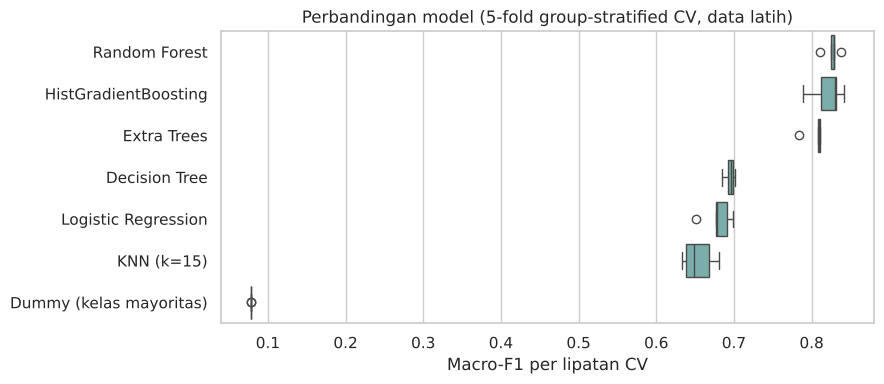

In [ ]:
from sklearn.model_selection import cross_validate  # fungsi cross-validation
from sklearn.metrics import make_scorer, cohen_kappa_score, accuracy_score, f1_score, balanced_accuracy_score, mean_absolute_error  # metrik evaluasi
from sklearn.dummy import DummyClassifier  # baseline tebakan
from sklearn.linear_model import LogisticRegression  # model linear
from sklearn.neighbors import KNeighborsClassifier  # model berbasis jarak
from sklearn.tree import DecisionTreeClassifier  # pohon keputusan
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier  # model ensemble

SCORING = {  # kumpulan metrik untuk CV
    "accuracy": "accuracy",  # akurasi
    "f1_macro": "f1_macro",  # F1 rata-rata antar kelas
    "balanced_accuracy": "balanced_accuracy",  # akurasi seimbang
    "qwk": make_scorer(cohen_kappa_score, weights="quadratic"),  # kappa berbobot kuadrat
}  # akhir metrik
cv5 = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)  # skema CV pada data latih


def run_cv(name, pipe):  # jalankan CV untuk satu pipeline
    res = cross_validate(pipe, X_train, y_train, groups=g_train, cv=cv5, scoring=SCORING, n_jobs=-1)  # CV paralel
    row = {"model": name}  # baris hasil
    for m in SCORING:  # untuk tiap metrik
        row[f"{m}_mean"] = res[f"test_{m}"].mean()  # rata-rata antar lipatan
        row[f"{m}_std"] = res[f"test_{m}"].std()  # simpangan baku antar lipatan
    return row, res["test_f1_macro"]  # kembalikan ringkasan dan skor per lipatan


candidates = {  # model pembanding (estimator, perlu scaling?)
    "Dummy (kelas mayoritas)": (DummyClassifier(strategy="most_frequent"), False),  # baseline tebakan
    "Logistic Regression": (LogisticRegression(max_iter=3000, class_weight="balanced"), True),  # linear
    "KNN (k=15)": (KNeighborsClassifier(n_neighbors=15), True),  # berbasis jarak
    "Decision Tree": (DecisionTreeClassifier(max_depth=8, class_weight="balanced", random_state=SEED), False),  # pohon tunggal
    "Random Forest": (RandomForestClassifier(n_estimators=300, class_weight="balanced", n_jobs=-1, random_state=SEED), False),  # hutan acak
    "Extra Trees": (ExtraTreesClassifier(n_estimators=300, class_weight="balanced", n_jobs=-1, random_state=SEED), False),  # pohon acak ekstrem
    "HistGradientBoosting": (HistGradientBoostingClassifier(random_state=SEED), False),  # boosting
}  # akhir kandidat

rows, fold_scores = [], {}  # penampung hasil
for name, (est, scale) in candidates.items():  # tiap kandidat
    r, fs = run_cv(name, build_pipeline(est, FEATURES_NUM, FEATURES_CAT, scale=scale))  # jalankan CV
    rows.append(r)  # simpan ringkasan
    fold_scores[name] = fs  # simpan skor per lipatan
    print(f"{name:26s} macro-F1 = {r['f1_macro_mean']:.3f} +/- {r['f1_macro_std']:.3f}")  # cetak progres

feat_train = nu.prepare_features(X_train)  # fitur turunan data latih untuk baseline rule-based
rule_pred = nu.rule_based_grade(feat_train)  # prediksi rumus tanpa ML
rule_row = {"model": "Rule-based (rumus poin tanpa ML)", "accuracy_mean": accuracy_score(y_train, rule_pred), "f1_macro_mean": f1_score(y_train, rule_pred, average="macro"),  # metrik rule-based
            "balanced_accuracy_mean": balanced_accuracy_score(y_train, rule_pred), "qwk_mean": cohen_kappa_score(y_train, rule_pred, weights="quadratic")}  # lanjutan metrik
cv_table = pd.concat([pd.DataFrame(rows), pd.DataFrame([rule_row])], ignore_index=True).sort_values("f1_macro_mean", ascending=False)  # gabungkan dan urutkan
display(cv_table[["model", "accuracy_mean", "f1_macro_mean", "f1_macro_std", "balanced_accuracy_mean", "qwk_mean"]].round(3))  # tampilkan tabel

plt.figure(figsize=(9, 4))  # ukuran grafik
order = [m for m in cv_table["model"] if m in fold_scores]  # urutan model
sns.boxplot(data=pd.DataFrame({k: fold_scores[k] for k in order}), orient="h", color="#72B7B2")  # sebaran skor antar lipatan
plt.xlabel("Macro-F1 per lipatan CV")  # label sumbu
plt.title("Perbandingan model (5-fold group-stratified CV, data latih)")  # judul
plt.tight_layout()  # rapikan
plt.show()  # tampilkan

## 10. Tuning Hyperparameter (Random Search + CV berkelompok)
Dua model terbaik berbasis pohon disetel dengan `RandomizedSearchCV` (skor: macro-F1, CV 3-lipatan berkelompok **di dalam data latih**). Data uji tidak disentuh.

In [ ]:
from sklearn.model_selection import RandomizedSearchCV  # pencarian acak hyperparameter
from scipy.stats import loguniform  # distribusi log-uniform untuk learning rate

cv3 = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED)  # CV dalam untuk tuning
space_rf = {  # ruang pencarian Random Forest
    "model__n_estimators": [200, 400, 600],  # jumlah pohon
    "model__max_depth": [None, 12, 20, 30],  # kedalaman maksimum
    "model__min_samples_leaf": [1, 2, 4],  # minimum sampel per daun
    "model__max_features": ["sqrt", 0.3, 0.5],  # fitur per split
}  # akhir ruang RF
space_hgb = {  # ruang pencarian HistGradientBoosting
    "model__learning_rate": loguniform(0.02, 0.2),  # kecepatan belajar
    "model__max_iter": [200, 300, 500],  # jumlah iterasi
    "model__max_leaf_nodes": [15, 31, 63],  # jumlah daun maksimum
    "model__min_samples_leaf": [10, 20, 40],  # minimum sampel per daun
    "model__l2_regularization": loguniform(1e-3, 10),  # regularisasi L2
}  # akhir ruang HGB

search_rf = RandomizedSearchCV(build_pipeline(RandomForestClassifier(class_weight="balanced", n_jobs=-1, random_state=SEED), FEATURES_NUM, FEATURES_CAT),  # pipeline RF
                               space_rf, n_iter=10, scoring="f1_macro", cv=cv3, random_state=SEED, n_jobs=-1, refit=True)  # pengaturan pencarian RF
search_hgb = RandomizedSearchCV(build_pipeline(HistGradientBoostingClassifier(random_state=SEED), FEATURES_NUM, FEATURES_CAT),  # pipeline HGB
                                space_hgb, n_iter=15, scoring="f1_macro", cv=cv3, random_state=SEED, n_jobs=-1, refit=True)  # pengaturan pencarian HGB
search_rf.fit(X_train, y_train, groups=g_train)  # cari parameter RF terbaik
search_hgb.fit(X_train, y_train, groups=g_train)  # cari parameter HGB terbaik
show_params = lambda d: {k.replace("model__", ""): (round(float(v), 4) if isinstance(v, (float, np.floating)) else v) for k, v in d.items()}  # rapikan tampilan parameter
print("RF  terbaik  :", show_params(search_rf.best_params_), "| F1 =", round(search_rf.best_score_, 4))  # laporan RF
print("HGB terbaik  :", show_params(search_hgb.best_params_), "| F1 =", round(search_hgb.best_score_, 4))  # laporan HGB

RF  terbaik  : {'n_estimators': 600, 'min_samples_leaf': 1, 'max_features': 0.3, 'max_depth': None} | F1 = 0.8093
HGB terbaik  : {'l2_regularization': 0.0165, 'learning_rate': 0.067, 'max_iter': 200, 'max_leaf_nodes': 15, 'min_samples_leaf': 40} | F1 = 0.8157


## 11. Klasifikasi Lanjutan: Model Ordinal dan Ensemble
Grade Nutri-Score **berurutan**, tetapi klasifikasi biasa menganggap semua kesalahan sama berat. Dua peningkatan diuji:
1. **Klasifier ordinal (Frank & Hall)**: 4 model biner untuk `P(grade > A)`, `P(grade > B)`, `P(grade > C)`, `P(grade > D)`; probabilitas tiap grade diperoleh dari selisihnya. Struktur urutan ikut dipelajari model.
2. **Soft-voting ensemble** dari Random Forest dan HistGradientBoosting hasil tuning.

Semua kandidat dibandingkan dengan **CV 5-lipatan pada data latih** dan pemenang dipilih otomatis berdasar macro-F1 (bukan berdasar data uji).

In [ ]:
from sklearn.base import clone  # menyalin estimator
from sklearn.ensemble import VotingClassifier  # ensemble voting

best_rf = clone(search_rf.best_estimator_.named_steps["model"])  # RF dengan parameter terbaik (belum dilatih)
best_hgb = clone(search_hgb.best_estimator_.named_steps["model"])  # HGB dengan parameter terbaik (belum dilatih)
final_candidates = {  # kandidat final
    "RF (tuned)": build_pipeline(clone(best_rf), FEATURES_NUM, FEATURES_CAT),  # RF tuning
    "HGB (tuned)": build_pipeline(clone(best_hgb), FEATURES_NUM, FEATURES_CAT),  # HGB tuning
    "Ordinal-HGB (tuned)": build_pipeline(nu.OrdinalClassifier(clone(best_hgb)), FEATURES_NUM, FEATURES_CAT),  # model ordinal
    "Voting RF+HGB (soft)": build_pipeline(VotingClassifier([("rf", clone(best_rf)), ("hgb", clone(best_hgb))], voting="soft"), FEATURES_NUM, FEATURES_CAT),  # ensemble
}  # akhir kandidat final

rows2, fold2 = [], {}  # penampung hasil
for name, pipe in final_candidates.items():  # tiap kandidat final
    r, fs = run_cv(name, pipe)  # jalankan CV 5-lipatan
    rows2.append(r)  # simpan baris
    fold2[name] = fs  # simpan skor per lipatan
cv_final = pd.DataFrame(rows2).sort_values("f1_macro_mean", ascending=False).reset_index(drop=True)  # urutkan kandidat
display(cv_final[["model", "accuracy_mean", "f1_macro_mean", "f1_macro_std", "balanced_accuracy_mean", "qwk_mean"]].round(4))  # tampilkan hasil

best_name = cv_final.loc[0, "model"]  # nama pemenang berdasarkan CV
final_pipe = final_candidates[best_name]  # pipeline pemenang
print(f"\nModel final terpilih (berdasarkan CV macro-F1 pada data latih): {best_name}")  # umumkan pemenang

,model,accuracy_mean,f1_macro_mean,f1_macro_std,balanced_accuracy_mean,qwk_mean
0,RF (tuned),0.8360,0.8300,0.0133,0.8307,0.9337
1,Ordinal-HGB (tuned),0.8326,0.8263,0.0238,0.8261,0.9321
2,Voting RF+HGB (soft),0.8314,0.8251,0.0194,0.8245,0.9287
3,HGB (tuned),0.8312,0.8250,0.0166,0.8239,0.9272



Model final terpilih (berdasarkan CV macro-F1 pada data latih): RF (tuned)


## 12. Evaluasi Akhir pada Data Uji (dipakai satu kali)
Model pemenang dilatih pada seluruh data latih lalu diuji pada data uji yang belum pernah disentuh. Selain metrik standar, dilaporkan **selang kepercayaan 95% (bootstrap)** agar jelas seberapa stabil angkanya, serta **proporsi kesalahan yang hanya selisih satu grade** (kesalahan "dekat").

Akurasi            : 0.841  (95% CI 0.815-0.863)
Macro-F1           : 0.837  (95% CI 0.809-0.860)
Balanced accuracy  : 0.836
QWK                : 0.936
MAE (langkah grade): 0.186
Salah <= 1 grade   : 97.6%

              precision    recall  f1-score   support

           A      0.892     0.902     0.897       164
           B      0.760     0.742     0.751       128
           C      0.806     0.822     0.814       213
           D      0.828     0.832     0.830       179
           E      0.902     0.883     0.892       197

    accuracy                          0.841       881
   macro avg      0.837     0.836     0.837       881
weighted avg      0.841     0.841     0.841       881



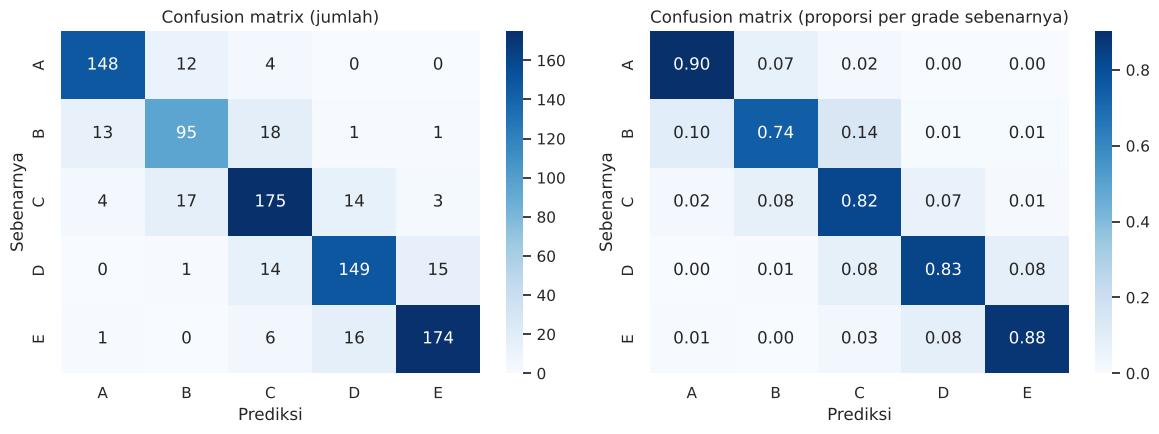

,model,accuracy,macro_f1,qwk
0,Dummy,0.242,0.078,0.000
1,Rule-based (tanpa ML),0.409,0.404,0.693
2,RF (tuned) (final),0.841,0.837,0.936


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix  # laporan klasifikasi dan matriks konfusi

final_pipe.fit(X_train, y_train)  # latih pemenang pada seluruh data latih
pred = final_pipe.predict(X_test)  # prediksi data uji
proba = final_pipe.predict_proba(X_test)  # probabilitas data uji

metrics = {  # kumpulan metrik uji
    "accuracy": accuracy_score(y_test, pred),  # akurasi
    "macro_f1": f1_score(y_test, pred, average="macro"),  # macro-F1
    "weighted_f1": f1_score(y_test, pred, average="weighted"),  # weighted-F1
    "balanced_accuracy": balanced_accuracy_score(y_test, pred),  # akurasi seimbang
    "qwk": cohen_kappa_score(y_test, pred, weights="quadratic"),  # kappa berbobot
    "mae_grade_steps": mean_absolute_error(y_test, pred),  # rata-rata selisih grade
    "within_1_grade": float((np.abs(y_test - pred) <= 1).mean()),  # proporsi salah maksimal 1 grade
}  # akhir metrik

rng = np.random.default_rng(SEED)  # generator acak untuk bootstrap
boot_f1, boot_acc = [], []  # hasil bootstrap
for _ in range(1000):  # 1000 resampling
    idx = rng.integers(0, len(y_test), len(y_test))  # indeks sampel berpengembalian
    boot_f1.append(f1_score(y_test[idx], pred[idx], average="macro"))  # macro-F1 sampel
    boot_acc.append(accuracy_score(y_test[idx], pred[idx]))  # akurasi sampel
ci_f1 = np.percentile(boot_f1, [2.5, 97.5])  # selang 95% macro-F1
ci_acc = np.percentile(boot_acc, [2.5, 97.5])  # selang 95% akurasi

print(f"Akurasi            : {metrics['accuracy']:.3f}  (95% CI {ci_acc[0]:.3f}-{ci_acc[1]:.3f})")  # akurasi + CI
print(f"Macro-F1           : {metrics['macro_f1']:.3f}  (95% CI {ci_f1[0]:.3f}-{ci_f1[1]:.3f})")  # F1 + CI
print(f"Balanced accuracy  : {metrics['balanced_accuracy']:.3f}")  # balanced acc
print(f"QWK                : {metrics['qwk']:.3f}")  # kappa
print(f"MAE (langkah grade): {metrics['mae_grade_steps']:.3f}")  # MAE
print(f"Salah <= 1 grade   : {metrics['within_1_grade']:.1%}")  # kesalahan dekat
print()  # baris kosong
print(classification_report(y_test, pred, target_names=GRADES, digits=3))  # laporan per kelas

cm = confusion_matrix(y_test, pred)  # matriks konfusi (jumlah)
cm_norm = confusion_matrix(y_test, pred, normalize="true")  # matriks konfusi (proporsi per baris)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))  # dua panel
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=GRADES, yticklabels=GRADES, ax=ax[0])  # jumlah
ax[0].set_title("Confusion matrix (jumlah)")  # judul
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", xticklabels=GRADES, yticklabels=GRADES, ax=ax[1])  # proporsi
ax[1].set_title("Confusion matrix (proporsi per grade sebenarnya)")  # judul
for a in ax:  # label sumbu
    a.set_xlabel("Prediksi")  # sumbu x
    a.set_ylabel("Sebenarnya")  # sumbu y
plt.tight_layout()  # rapikan
plt.show()  # tampilkan

comp = []  # pembanding di data uji
dummy_pred = DummyClassifier(strategy="most_frequent").fit(X_train, y_train).predict(X_test)  # prediksi dummy
rule_test = nu.rule_based_grade(nu.prepare_features(X_test))  # prediksi rule-based
for nm, pr in [("Dummy", dummy_pred), ("Rule-based (tanpa ML)", rule_test), (f"{best_name} (final)", pred)]:  # tiga model
    comp.append([nm, accuracy_score(y_test, pr), f1_score(y_test, pr, average="macro"), cohen_kappa_score(y_test, pr, weights="quadratic")])  # simpan metrik
display(pd.DataFrame(comp, columns=["model", "accuracy", "macro_f1", "qwk"]).round(3))  # tampilkan perbandingan

## 13. Studi Ablasi Fitur (apa yang benar-benar membantu?)
Ablasi menambahkan kelompok fitur satu per satu dan mengukur macro-F1 (CV 5-lipatan berkelompok, model HistGradientBoosting bawaan agar cepat). Ini menjawab pertanyaan penelitian #2 dan sekaligus **memeriksa kebocoran**: bila menambah `nova_group`/`ecoscore_grade` mengubah hasil sangat besar, berarti keduanya adalah proksi target.

,skenario,macro_f1,std,accuracy,qwk
0,S1 Nutrisi mentah,0.7865,0.0167,0.7951,0.9009
1,S2 + Rasio,0.7883,0.0154,0.7962,0.9057
2,S3 + Poin Nutri-Score,0.8114,0.0149,0.8184,0.9129
3,S4 + Kategori produk,0.8302,0.0209,0.8368,0.9305
4,S5 + Alergen (model final),0.8211,0.0185,0.8289,0.9243
5,"S6 + NOVA & Ecoscore (diuji, tidak dipakai)",0.8290,0.0164,0.8365,0.9338


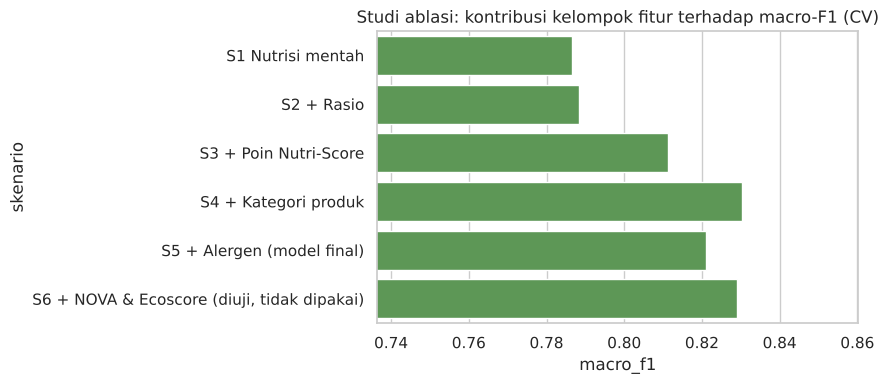

In [ ]:
scenarios = {  # skenario ablasi: (kolom numerik, kolom kategorikal)
    "S1 Nutrisi mentah": (nu.NUTRIENT_COLS, []),  # hanya 9 kolom gizi
    "S2 + Rasio": (nu.NUTRIENT_COLS + nu.ENGINEERED_NUM, []),  # tambah rasio
    "S3 + Poin Nutri-Score": (nu.NUTRIENT_COLS + nu.ENGINEERED_NUM + nu.POINT_NUM, []),  # tambah poin domain
    "S4 + Kategori produk": (nu.NUTRIENT_COLS + nu.ENGINEERED_NUM + nu.POINT_NUM + nu.CATEGORY_FLAGS, nu.CATEGORY_CAT),  # tambah kategori
    "S5 + Alergen (model final)": (FEATURES_NUM, FEATURES_CAT),  # fitur model utama
    "S6 + NOVA & Ecoscore (diuji, tidak dipakai)": (FEATURES_NUM + ["nova_group"], FEATURES_CAT + ["ecoscore_grade"]),  # skor turunan lain
}  # akhir skenario
X_train_abl = X.iloc[train_idx]  # data latih dengan kolom nova/eco
abl_rows = []  # hasil ablasi
for name, (num_c, cat_c) in scenarios.items():  # tiap skenario
    pipe = build_pipeline(HistGradientBoostingClassifier(random_state=SEED), num_c, cat_c)  # pipeline skenario
    res = cross_validate(pipe, X_train_abl, y_train, groups=g_train, cv=cv5, scoring=SCORING, n_jobs=-1)  # CV
    abl_rows.append([name, res["test_f1_macro"].mean(), res["test_f1_macro"].std(), res["test_accuracy"].mean(), res["test_qwk"].mean()])  # simpan
ablation = pd.DataFrame(abl_rows, columns=["skenario", "macro_f1", "std", "accuracy", "qwk"])  # tabel ablasi
display(ablation.round(4))  # tampilkan tabel

plt.figure(figsize=(9, 4))  # ukuran grafik
sns.barplot(data=ablation, y="skenario", x="macro_f1", color="#54A24B")  # bar macro-F1 per skenario
plt.xlim(max(0, ablation["macro_f1"].min() - 0.05), min(1, ablation["macro_f1"].max() + 0.03))  # zoom sumbu agar beda terlihat
plt.title("Studi ablasi: kontribusi kelompok fitur terhadap macro-F1 (CV)")  # judul
plt.tight_layout()  # rapikan
plt.show()  # tampilkan

**Cara membaca ablasi:** bandingkan selisih antar skenario dengan simpangan baku antar lipatan (kolom `std`). Selisih yang lebih kecil dari `std` dianggap *tidak bermakna* (hanya noise). Kelompok fitur yang tidak memberi kenaikan jelas tetap dilaporkan apa adanya; jangan disembunyikan.

## 14. Interpretasi Model (Permutation Importance)
*Permutation importance* mengacak satu kolom mentah pada data uji dan mengukur penurunan macro-F1. Kolom `categories` mewakili **seluruh** fitur turunan kategori (flag + kategori utama) sebagai satu kelompok.

,kolom_mentah,penurunan_f1,std
0,sugars_100g,0.2964,0.0154
1,saturated_fat_100g,0.2747,0.0091
2,sodium_100g,0.2416,0.0088
3,energy_kcal,0.2014,0.0107
4,fat_100g,0.1838,0.0059
5,proteins_100g,0.1734,0.0084
6,carbs_100g,0.1679,0.0089
7,fiber_100g,0.1374,0.0145
8,categories,0.0321,0.0041
9,salt_100g,0.0064,0.0034


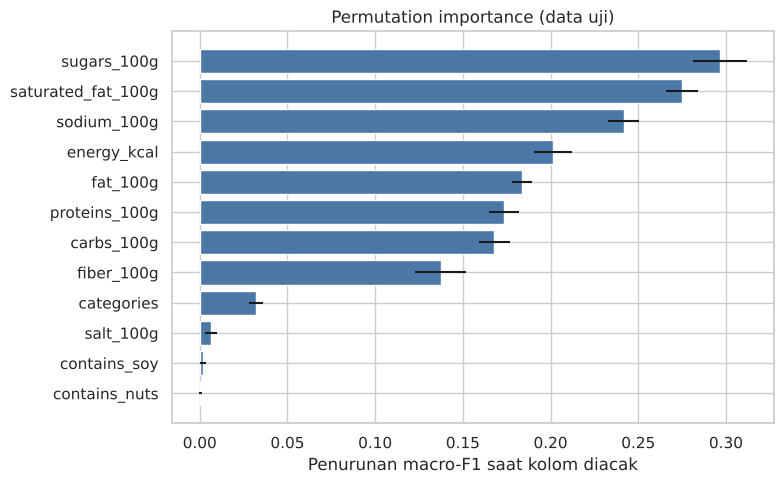

In [ ]:
from sklearn.inspection import permutation_importance  # fungsi importance berbasis pengacakan

perm = permutation_importance(final_pipe, X_test, y_test, scoring="f1_macro", n_repeats=10, random_state=SEED, n_jobs=-1)  # hitung importance
imp = pd.DataFrame({"kolom_mentah": X_test.columns, "penurunan_f1": perm.importances_mean, "std": perm.importances_std})  # tabel importance
imp = imp.sort_values("penurunan_f1", ascending=False).reset_index(drop=True)  # urutkan
display(imp.head(12).round(4))  # tampilkan 12 teratas

plt.figure(figsize=(8, 5))  # ukuran grafik
top = imp.head(12).iloc[::-1]  # 12 teratas, dibalik agar terbesar di atas
plt.barh(top["kolom_mentah"], top["penurunan_f1"], xerr=top["std"], color="#4C78A8")  # bar horizontal dengan galat
plt.xlabel("Penurunan macro-F1 saat kolom diacak")  # label sumbu
plt.title("Permutation importance (data uji)")  # judul
plt.tight_layout()  # rapikan
plt.show()  # tampilkan

## 15. Analisis Error
Model yang baik bukan hanya skor tinggi, tetapi **paham di mana ia lemah**. Bagian ini melihat performa per kategori produk, pengaruh data serat yang kosong, dan contoh produk yang salah diprediksi.

In [ ]:
test_feat = nu.prepare_features(X_test).reset_index(drop=True)  # fitur turunan data uji
err = pd.DataFrame({  # tabel prediksi uji
    "product": df.loc[test_idx, "product_name"].to_numpy(),  # nama produk
    "kategori": test_feat["main_category"].to_numpy(),  # kategori utama
    "benar": y_test, "prediksi": pred,  # label asli dan prediksi
    "fiber_kosong": test_feat["fiber_missing"].to_numpy(),  # penanda serat kosong
    "minuman": test_feat["is_beverage"].to_numpy(),  # penanda minuman
    "skor_poin": test_feat["nutri_points"].to_numpy(),  # skor poin pendekatan
})  # akhir tabel
err["akurat"] = (err["benar"] == err["prediksi"]).astype(int)  # penanda prediksi tepat

by_cat = err.groupby("kategori").agg(n=("akurat", "size"), akurasi=("akurat", "mean")).query("n >= 25").sort_values("akurasi")  # akurasi per kategori (n>=25)
print("Akurasi per kategori produk (minimal 25 produk uji):")  # judul
display(by_cat.round(3))  # tampilkan tabel

print("\nAkurasi berdasarkan ketersediaan data serat:")  # judul
display(err.groupby("fiber_kosong")["akurat"].agg(["size", "mean"]).rename(index={0: "serat tersedia", 1: "serat kosong"}).round(3))  # perbandingan serat
print("\nAkurasi minuman vs bukan minuman:")  # judul
display(err.groupby("minuman")["akurat"].agg(["size", "mean"]).rename(index={0: "bukan minuman", 1: "minuman"}).round(3))  # perbandingan minuman

wrong = err[err["akurat"] == 0].copy()  # produk yang salah
wrong["benar"] = wrong["benar"].map(dict(enumerate(GRADES)))  # ubah angka ke huruf
wrong["prediksi"] = wrong["prediksi"].map(dict(enumerate(GRADES)))  # ubah angka ke huruf
print(f"\nContoh kesalahan (dari {len(wrong)} kesalahan uji):")  # judul
display(wrong.sample(min(10, len(wrong)), random_state=SEED)[["product", "kategori", "benar", "prediksi", "skor_poin", "fiber_kosong"]])  # contoh acak

Akurasi per kategori produk (minimal 25 produk uji):


,n,akurasi
kategori,,
en:beverages-and-beverages-preparations,92,0.761
en:condiments,60,0.800
en:plant-based-foods-and-beverages,340,0.812
en:dairies,119,0.891
en:snacks,168,0.899



Akurasi berdasarkan ketersediaan data serat:


,size,mean
fiber_kosong,,
serat tersedia,650,0.838
serat kosong,231,0.848



Akurasi minuman vs bukan minuman:


,size,mean
minuman,,
bukan minuman,435,0.883
minuman,446,0.800



Contoh kesalahan (dari 140 kesalahan uji):


,product,kategori,benar,prediksi,skor_poin,fiber_kosong
673,Totas,en:snacks,E,D,13.0,0
409,Oasis Pomme Cassis Framboise,en:beverages-and-beverages-preparations,D,E,1.0,1
202,Vegetable and roast chicken soup,en:meals,C,B,1.0,0
746,Skyr sur lit aux myrtilles,en:dairies,B,A,-2.0,1
299,Barritas de Espelta Sabor Manzana 0%,en:snacks,A,B,-2.0,0
60,kefir drink original,en:beverages-and-beverages-preparations,B,C,0.0,1
482,Super Smoothie Antioxydant,en:beverages-and-beverages-preparations,D,E,1.0,0
432,Jutos,en:plant-based-foods-and-beverages,D,E,4.0,1
657,Limonata,en:plant-based-foods-and-beverages,D,E,1.0,0
677,American sandwich Céréales,en:plant-based-foods-and-beverages,A,B,-3.0,0


**Cara menafsirkan:** kategori dengan akurasi rendah biasanya adalah produk yang memakai aturan Nutri-Score khusus (minuman, lemak/minyak, keju) atau yang bergantung pada informasi yang tidak ada di dataset (persentase buah/sayur/kacang). Itu keterbatasan data, bukan kesalahan model, dan dicantumkan pada kesimpulan.

## 16. Menyimpan Model, Laporan, dan API (siap deployment)
Pipeline lengkap (rekayasa fitur + pra-pemrosesan + model) disimpan dalam satu file `.joblib`. Metadata (versi library, seed, fitur, metrik) disimpan agar eksperimen **dapat direproduksi**. Sel terakhir menulis contoh API **FastAPI** sehingga model dapat dipanggil lewat REST (sesuai materi *Model Serving* bootcamp).

In [ ]:
import datetime  # untuk stempel waktu metadata
model_path = f"{OUT_DIR}/nutriscore_pipeline.joblib"  # lokasi file model
joblib.dump(final_pipe, model_path)  # simpan pipeline lengkap
metadata = {  # metadata eksperimen
    "dibuat": datetime.datetime.now().isoformat(timespec="seconds"),  # waktu
    "model_final": best_name,  # nama model
    "seed": SEED,  # seed
    "kelas": GRADES,  # urutan kelas
    "n_train": int(len(X_train)), "n_test": int(len(X_test)),  # ukuran data
    "fitur_numerik": FEATURES_NUM, "fitur_kategorikal": FEATURES_CAT,  # daftar fitur
    "kolom_input_mentah": nu.RAW_INPUT_COLS,  # kolom input API
    "metrik_uji": {k: round(float(v), 4) for k, v in metrics.items()},  # metrik uji
    "ci95_macro_f1": [round(float(ci_f1[0]), 4), round(float(ci_f1[1]), 4)],  # selang kepercayaan F1
    "versi": {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__, "sklearn": sklearn.__version__},  # versi library
}  # akhir metadata
with open(f"{OUT_DIR}/metadata.json", "w", encoding="utf-8") as f:  # buka file metadata
    json.dump(metadata, f, indent=2, ensure_ascii=False)  # tulis JSON
cv_final.to_csv(f"{OUT_DIR}/cv_final_models.csv", index=False)  # simpan hasil CV final
cv_table.to_csv(f"{OUT_DIR}/cv_all_models.csv", index=False)  # simpan hasil CV semua model
ablation.to_csv(f"{OUT_DIR}/ablation.csv", index=False)  # simpan ablasi
imp.to_csv(f"{OUT_DIR}/permutation_importance.csv", index=False)  # simpan importance

loaded = joblib.load(model_path)  # uji muat ulang model
sample = X_test.head(3)  # tiga produk contoh
print("Prediksi ulang dari file model :", [GRADES[i] for i in loaded.predict(sample)])  # prediksi hasil muat
print("Grade sebenarnya               :", [GRADES[i] for i in y_test[:3]])  # label asli

Prediksi ulang dari file model : ['B', 'D', 'A']
Grade sebenarnya               : ['B', 'D', 'A']


In [ ]:
%%writefile app.py
# API sederhana untuk menyajikan model Nutri-Score (jalankan: uvicorn app:app --reload)
from typing import Optional  # tipe opsional
import joblib  # memuat model
import pandas as pd  # tabel data
from fastapi import FastAPI  # framework API
from pydantic import BaseModel  # validasi input
import nutriscore_utils as nu  # modul fitur (dibutuhkan agar pipeline bisa dimuat)

GRADES = ["A", "B", "C", "D", "E"]  # urutan grade
model = joblib.load("outputs_nutriscore/nutriscore_pipeline.joblib")  # muat pipeline
app = FastAPI(title="Nutri-Score Classifier", version="1.0")  # buat aplikasi


class Product(BaseModel):  # skema input produk
    energy_kcal: Optional[float] = None  # energi per 100 g
    fat_100g: Optional[float] = None  # lemak
    saturated_fat_100g: Optional[float] = None  # lemak jenuh
    carbs_100g: Optional[float] = None  # karbohidrat
    sugars_100g: Optional[float] = None  # gula
    fiber_100g: Optional[float] = None  # serat
    proteins_100g: Optional[float] = None  # protein
    salt_100g: Optional[float] = None  # garam
    sodium_100g: Optional[float] = None  # natrium
    categories: str = ""  # teks kategori produk
    contains_gluten: bool = False  # alergen gluten
    contains_dairy: bool = False  # alergen susu
    contains_nuts: bool = False  # alergen kacang
    contains_soy: bool = False  # alergen kedelai
    contains_eggs: bool = False  # alergen telur
    contains_fish: bool = False  # alergen ikan


@app.get("/health")  # endpoint cek layanan
def health():  # fungsi cek
    return {"status": "ok"}  # respons sederhana


@app.post("/predict")  # endpoint prediksi
def predict(p: Product):  # terima data produk
    row = pd.DataFrame([p.model_dump()])[nu.RAW_INPUT_COLS]  # susun satu baris sesuai kolom model
    proba = model.predict_proba(row)[0]  # probabilitas tiap grade
    return {  # respons JSON
        "grade": GRADES[int(proba.argmax())],  # grade prediksi
        "probabilities": {g: round(float(v), 4) for g, v in zip(GRADES, proba)},  # probabilitas per grade
    }  # akhir respons

Writing app.py


In [ ]:
with open("requirements.txt", "w") as f:  # tulis daftar dependensi
    f.write(f"pandas\nnumpy\nscipy\nscikit-learn=={sklearn.__version__}\njoblib\nfastapi\nuvicorn\n")  # versi sklearn dikunci agar model bisa dimuat
print(open("requirements.txt").read())  # tampilkan isi
print("Jalankan API  : uvicorn app:app --reload")  # petunjuk menjalankan API
print("Dokumentasi   : http://127.0.0.1:8000/docs")  # alamat dokumentasi otomatis

pandas
numpy
scipy
scikit-learn==1.9.1
joblib
fastapi
uvicorn

Jalankan API  : uvicorn app:app --reload
Dokumentasi   : http://127.0.0.1:8000/docs


## 17. Kesimpulan, Keterbatasan, dan Pengembangan Lanjut
Sel di bawah menyusun ringkasan **otomatis dari hasil yang benar-benar dihitung** (angka tidak diketik manual), termasuk draf poin CV.

In [ ]:
base_row = cv_table[cv_table["model"].str.startswith("Dummy")].iloc[0]  # baris baseline dummy
rule_r = cv_table[cv_table["model"].str.startswith("Rule")].iloc[0]  # baris rule-based
s2 = ablation.loc[ablation["skenario"].str.startswith("S2"), "macro_f1"].iloc[0]  # F1 skenario S2
s3 = ablation.loc[ablation["skenario"].str.startswith("S3"), "macro_f1"].iloc[0]  # F1 skenario S3
s1 = ablation.loc[ablation["skenario"].str.startswith("S1"), "macro_f1"].iloc[0]  # F1 skenario S1
s4 = ablation.loc[ablation["skenario"].str.startswith("S4"), "macro_f1"].iloc[0]  # F1 skenario S4
s5 = ablation.loc[ablation["skenario"].str.startswith("S5"), "macro_f1"].iloc[0]  # F1 skenario S5
std5 = ablation.loc[ablation["skenario"].str.startswith("S5"), "std"].iloc[0]  # simpangan baku antar lipatan S5
s6 = ablation.loc[ablation["skenario"].str.startswith("S6"), "macro_f1"].iloc[0]  # F1 skenario S6
print("RINGKASAN HASIL")  # judul
print("=" * 70)  # garis
print(f"1. Model final: {best_name}. Pada data uji (n={len(y_test):,}, grup produk terpisah dari data latih):")  # model final
print(f"   akurasi {metrics['accuracy']:.1%} (CI95 {ci_acc[0]:.1%}-{ci_acc[1]:.1%}), macro-F1 {metrics['macro_f1']:.3f} (CI95 {ci_f1[0]:.3f}-{ci_f1[1]:.3f}), QWK {metrics['qwk']:.3f}.")  # metrik
print(f"2. Baseline: dummy macro-F1 {base_row['f1_macro_mean']:.3f}; rumus poin tanpa ML macro-F1 {rule_r['f1_macro_mean']:.3f}. Model ML naik ke {cv_final.loc[0, 'f1_macro_mean']:.3f} (CV).")  # baseline
print(f"3. {metrics['within_1_grade']:.1%} prediksi berselisih maksimal satu grade; rata-rata selisih {metrics['mae_grade_steps']:.2f} grade.")  # kesalahan dekat
print(f"4. Ablasi: nutrisi mentah {s1:.3f} -> + rasio {s2:.3f} -> + poin Nutri-Score {s3:.3f} -> model final {s5:.3f}; menambah NOVA/Ecoscore menghasilkan {s6:.3f}.")  # ablasi
verdict = "tidak bermakna (di dalam noise antar lipatan)" if abs(s5 - s4) <= std5 else ("berguna" if s5 > s4 else "merugikan")  # penilaian objektif efek alergen
print(f"   Efek menambah alergen (S5 - S4) = {s5 - s4:+.3f} dengan std antar lipatan {std5:.3f} -> {verdict}. Dilaporkan apa adanya; alergen dipertahankan sebagai konteks produk, bukan sumber performa.")  # catatan alergen
print(f"5. Fitur paling berpengaruh (permutation importance): {', '.join(imp['kolom_mentah'].head(3))}.")  # importance
print()  # baris kosong
print("DRAF POIN CV (ganti angka bila Anda menjalankan ulang dengan data berbeda):")  # judul CV
print(f"- Built a leakage-safe ML pipeline (group-aware split, sklearn Pipeline) classifying {len(df):,} packaged foods into Nutri-Score grades A-E;")  # bullet 1
print(f"  final {best_name} reached {metrics['macro_f1']:.2f} macro-F1 / {metrics['accuracy']:.0%} accuracy on held-out products (baseline rule-based: {rule_r['f1_macro_mean']:.2f}).")  # bullet 1 lanjutan
print(f"- Engineered domain-driven features (approximate Nutri-Score points, category flags) and ran feature-group ablations; compared ordinal vs. nominal classifiers.")  # bullet 2
print(f"- Packaged the model with joblib and a FastAPI /predict endpoint for serving.")  # bullet 3

RINGKASAN HASIL
1. Model final: RF (tuned). Pada data uji (n=881, grup produk terpisah dari data latih):
   akurasi 84.1% (CI95 81.5%-86.3%), macro-F1 0.837 (CI95 0.809-0.860), QWK 0.936.
2. Baseline: dummy macro-F1 0.078; rumus poin tanpa ML macro-F1 0.394. Model ML naik ke 0.830 (CV).
3. 97.6% prediksi berselisih maksimal satu grade; rata-rata selisih 0.19 grade.
4. Ablasi: nutrisi mentah 0.786 -> + rasio 0.788 -> + poin Nutri-Score 0.811 -> model final 0.821; menambah NOVA/Ecoscore menghasilkan 0.829.
   Efek menambah alergen (S5 - S4) = -0.009 dengan std antar lipatan 0.018 -> tidak bermakna (di dalam noise antar lipatan). Dilaporkan apa adanya; alergen dipertahankan sebagai konteks produk, bukan sumber performa.
5. Fitur paling berpengaruh (permutation importance): sugars_100g, saturated_fat_100g, sodium_100g.

DRAF POIN CV (ganti angka bila Anda menjalankan ulang dengan data berbeda):
- Built a leakage-safe ML pipeline (group-aware split, sklearn Pipeline) classifying 4,405 packa

### Keterbatasan
- Dataset tidak memuat **persentase buah/sayur/kacang**, komponen penting algoritma Nutri-Score; ini batas atas performa yang realistis.
- Label berasal dari data crowdsourcing (Open Food Facts), sehingga mengandung noise pencatatan.
- Minuman, lemak/minyak, dan keju memakai aturan khusus dengan jumlah sampel kecil.
- Hanya satu pembagian train/test; hasil CV dan bootstrap CI dilaporkan untuk menunjukkan stabilitas.

### Pengembangan lanjut
- Tambahkan fitur dari teks `ingredients` (TF-IDF) untuk menangkap persentase buah/sayur.
- Bandingkan dengan XGBoost/LightGBM dan kalibrasi probabilitas.
- Tambahkan SHAP untuk penjelasan per produk.